In [1]:
import pickle
import pandas as pd
import ast
import sys, os
from deep_translator import GoogleTranslator
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))
from scripts.jaccard_similarity_bfmn import results_jaccard_similarities, plot_comparison

/Users/emma/projects/cognoscolab/myvenv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
path_rassereno_analysis = '/Users/emma/projects/cognoscolab/rassereno/out/analysis'

# Latex Table

## Functions

In [50]:
def translate_hubs_column(df, col="Hubs", source="it", target="en"):
    
    new_df = df.copy()
    # make sure the column contains actual lists, not strings
    new_df[col] = new_df[col].apply(ast.literal_eval)

    # collect all unique words across all rows
    unique_words = list({w.capitalize() for lst in new_df[col] for w in lst})

    # join into newline-separated block for one-shot translation
    joined = "\n".join(unique_words)

    # translate in one request
    translated_blob = GoogleTranslator(source=source, target=target).translate(joined)

    # split back
    translated_list = translated_blob.split("\n")

    # create mapping dict
    translations = dict(zip(unique_words, translated_list))

    # apply mapping back to df
    # df[col] = df[col].apply(lambda lst: [translations[w.capitalize()] for w in lst])
    new_df[col] = new_df[col].apply(lambda lst: ", ".join(translations[w.capitalize()] for w in lst))

    return new_df

In [51]:
def mapping_cols_df(features_df):
    keyword_map = {
        "ansia": "anxiety",
        "benessere": "wellbeing",
        "computer": "computer science", 
        "esame": "exam",
        "fisica": "physics",
        "scuola": "school",
        "informatica": "computer science",
        "insegnante": "teacher",
        "matematica": "mathematics",
        "math": "mathematics",
        "professore": "professor",
        "scienza": "science",
        "scuola": "school",
        "scienziato": "scientist (male)",
        "scienziata": "scientist (female)",
        "statistica": "statistics",
        "studente": "student",
        "universita": "university",
        "ricerca": "research",
        "voto": "grade",
    }
    sample_map = {
        "experts_2019": "Experts",
        "liceo_2019": "H-S South",
        "liceo_2025/high_anxiety": "H-Anx H-S",
        "liceo_2025/low_anxiety": "L-Anx H-S",
        "gpt_oss_high_school/high_anxiety": "GPT H-Anx H-S",
        "gpt_oss_high_school/low_anxiety": "GPT L-Anx H-S",
        "physics_students_2025": "Physics",
        "gpt_oss_physics": "GPT Physics",
        "psychology_students_filtered/high_anxiety": "H-Anx Psy",
        "psychology_students_filtered/low_anxiety": "L-Anx Psy",
        "gpt_oss_psychology/high_anxiety": "GPT H-Anx Psy",
        "gpt_oss_psychology/low_anxiety": "GPT L-Anx Psy",
    }

    if "keyword" in features_df.columns:  
        features_df["keyword"] = features_df["keyword"].map(keyword_map).fillna(features_df["keyword"])

    features_df["Sample"] = features_df["Sample"].map(sample_map).fillna(features_df["Sample"])

    features_df_cleaned = translate_hubs_column(features_df, col="Hubs")
    
    return features_df_cleaned

## Feature keyword fmns

In [52]:
all_keyword_fmns_features = pd.read_csv(f'{path_rassereno_analysis}/features_keyword_fmns.csv')

In [53]:
keyword_fmns_features_cleaned = mapping_cols_df(all_keyword_fmns_features)

In [36]:
for keyword in keyword_fmns_features_cleaned['keyword'].unique():
    df_keyword = keyword_fmns_features_cleaned[keyword_fmns_features_cleaned['keyword'] == keyword].drop(columns=['keyword']).to_latex(
                                                                                       index=False,
                                                                                       escape=False,
                                                                                       float_format="%.2f", 
                                                                                       position="!hbpt", 
                                                                                       column_format ="lccccl",
                                                                                       caption=f"Network features for the semantic frame of \\textit{{{keyword.capitalize()}}}.",
                                                                                       label=f"tab:network_features_{keyword}",
                                                                                       )
    df_latex = df_keyword.replace(r"\begin{table}[!hbpt]", f"\\begin{{table}}[!hbpt]\n\\footnotesize\n\\centering")
    
    with open(f'{path_rassereno_analysis}/features_keyword_fmns_latex.txt', "a") as f:
        f.write(f"{df_latex}\n")

## Feature total fmns

In [56]:
all_tot_fmns_features = pd.read_csv(f'{path_rassereno_analysis}/features_tot_fmns.csv')

In [58]:
tot_fmns_features_cleaned = mapping_cols_df(all_tot_fmns_features)
tot_fmns_features_cleaned = tot_fmns_features_cleaned.drop(columns=['$N_v$','$N_e$', '$l_G$','$d$'])

In [59]:
tot_features_latex = tot_fmns_features_cleaned.to_latex(
    index=False,
    escape=False,
    float_format="%.2f", 
    position="!hbpt", 
    column_format ="lccccp{8cm}",
    caption="Network features for the total semantic frame of each sample.",
    label="tab:network_features_total",
    )
tot_features_latex = tot_features_latex.replace(r"\begin{table}[!hbpt]", f"\\begin{{table}}[!hbpt]\n\\footnotesize\n\\centering")

with open(f'{path_rassereno_analysis}/features_tot_fmns_latex.txt', "w") as f:
    f.write(f"{tot_features_latex}\n")

## Keywords

In [18]:
keywords_rassereno_eng = ['mathematics', 'statistics', 'physics', 'science', 'computer', 'research', 'exam','grade', 'professor', 'teacher', 'scientist', 'school', 'university', 'anxiety', 'wellbeing']

cap_keywords = [w.capitalize().replace("'", "") for w in keywords_rassereno_eng]

dict_words = {'Experiment 1' : [cap_keywords[:6]], 
              'Experiment 2' : [cap_keywords[6:13]], 
              'Experiment 3' : [cap_keywords[13:]]}
df_words = pd.DataFrame.from_dict(dict_words)
df_words.to_latex()

"\\begin{tabular}{llll}\n\\toprule\n & Experiment 1 & Experiment 2 & Experiment 3 \\\\\n\\midrule\n0 & ['Mathematics', 'Statistics', 'Physics', 'Science', 'Computer', 'Research'] & ['Exam', 'Grade', 'Professor', 'Teacher', 'Scientist', 'School', 'University'] & ['Anxiety', 'Wellbeing'] \\\\\n\\bottomrule\n\\end{tabular}\n"

# Jaccard Similarity

In [9]:
# features_df = pd.read_json('/Users/emma/projects/cognoscolab/rassereno/notebooks/all_fmnts.json')
with open(f'{path_rassereno_analysis}/bfmn/all_bfmns.pkl', 'rb') as f:
    features = pickle.load(f)

## Psychology students

In [10]:
low_anx_psychology = results_jaccard_similarities(features, 'gpt_oss_psychology_low_anx', 'psychology_low_anx')

gpt_oss_psychology_low_anx:
matematica - ansia: 0.0136986301369863
matematica - esame: 0.03278688524590164
esame - ansia: 0.03508771929824561

psychology_low_anx:
matematica - ansia: 0.03731343283582089
matematica - esame: 0.07079646017699115
esame - ansia: 0.15315315315315314


In [11]:
high_anx_psychology = results_jaccard_similarities(features, 'gpt_oss_psychology_high_anx', 'psychology_high_anx')

gpt_oss_psychology_high_anx:
matematica - ansia: 0.014925373134328358
matematica - esame: 0.03571428571428571
esame - ansia: 0.038461538461538464

psychology_high_anx:
matematica - ansia: 0.12837837837837837
matematica - esame: 0.10810810810810811
esame - ansia: 0.13385826771653545


## High school students 2025

In [12]:
low_anx_high_school = results_jaccard_similarities(features, 'gpt_oss_high_school_low_anx', 'high_school_low_anx')

gpt_oss_high_school_low_anx:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

high_school_low_anx:
matematica - ansia: 0.04
matematica - esame: 0.054945054945054944
esame - ansia: 0.08860759493670886


In [13]:
high_anx_high_school = results_jaccard_similarities(features, 'gpt_oss_high_school_high_anx', 'high_school_high_anx')

gpt_oss_high_school_high_anx:
matematica - ansia: 0.0
matematica - esame: 0.03225806451612903
esame - ansia: 0.0

high_school_high_anx:
matematica - ansia: 0.0546875
matematica - esame: 0.07407407407407407
esame - ansia: 0.07920792079207921


## Fisica

In [14]:
physics = results_jaccard_similarities(features, 'gpt_oss_physics', 'physics')

gpt_oss_physics:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

physics:
matematica - ansia: 0.0196078431372549
matematica - esame: 0.029411764705882353
esame - ansia: 0.05128205128205128


In [15]:
all_results = {**low_anx_psychology,
               **high_anx_psychology,
               **low_anx_high_school,
               **high_anx_high_school,
               **physics}

In [16]:
rows = []
for k, (v1, v2, v3) in all_results.items():
    source = 'GPT-oss' if 'gpt' in k else 'Humans'
    group = k.replace('gpt_oss_', '').replace('_', ' ').title()
    rows.append({'group': group, 'source': source, 'comparison_1': v1, 'comparison_2': v2, 'comparison_3':v3})

similarities = pd.DataFrame(rows).sort_values('group')
for col in ['comparison_1', 'comparison_2', 'comparison_3']:
    for idx in range(len(similarities[col])):
        if similarities.loc[idx, col] == 0:
            similarities.loc[idx, col] = 0.001

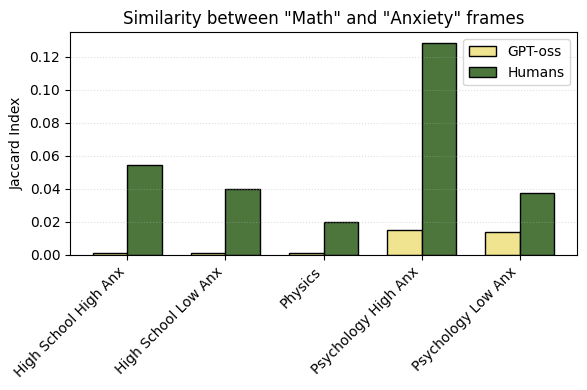

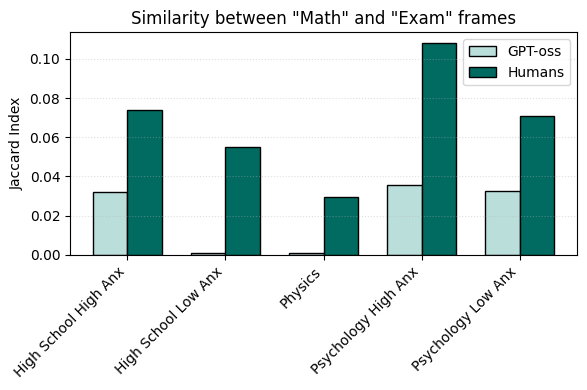

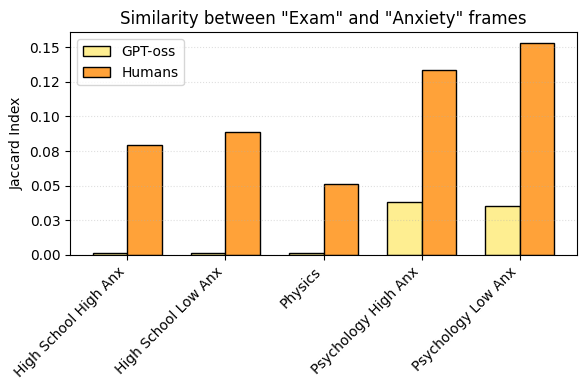

In [17]:
plot_comparison(similarities, 'comparison_1', 'Similarity between "Math" and "Anxiety" frames', '#F0E491', '#4C763B', path_rassereno_analysis)
plot_comparison(similarities, 'comparison_2', 'Similarity between "Math" and "Exam" frames','#BADFDB', '#016B61', path_rassereno_analysis)
plot_comparison(similarities, 'comparison_3', 'Similarity between "Exam" and "Anxiety" frames','#FEEE91', '#FFA239', path_rassereno_analysis)